<a href="https://colab.research.google.com/github/eduardozurek/ia/blob/main/_008_redes_neuronales_artificiales/01a_Modelos_Lineales_y_Minimos_Cuadrados.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Modelos lineales y mínimos cuadrados**

Tomado de: "The elements of statistical learning", sección 2.3.1

https://web.stanford.edu/~hastie/ElemStatLearn/

Partiendo de:

$\hat Y = \hat \beta_0+ \sum _{j=1} ^{p} X_j \hat \beta _j$

Escribiendo en forma matricial:

$\hat Y = X \hat \beta$

Donde:

$ \hat Y =
 \begin{pmatrix}
  \hat y_1 \\
  \hat y_2 \\
  \vdots\\
  \hat y_N
 \end{pmatrix}$

$ X =
 \begin{pmatrix}
  1 & x_{1,1} & x_{1,2} & \cdots & x_{1,p} \\
  1 & x_{2,1} & x_{2,2} & \cdots & x_{2,p} \\
  \vdots & \vdots  & \vdots  & \ddots & \vdots  \\
  1 & x_{N,1} & x_{N,2} & \cdots & x_{N,p}
 \end{pmatrix}$

$ \hat \beta =
 \begin{pmatrix}
  \hat \beta_0 \\
  \hat \beta_1 \\
  \vdots  \\
  \hat \beta_p
 \end{pmatrix}$

La idea en este proceso es estimar unos coeficientes $\beta$ que permitan minimizar el error cuadrático:

$RSS(\beta) = \sum _{i=1} ^{N} (y_i - X_i \beta) ^{2}$

En forma matricial:

$RSS(\beta) = (y-X\beta)^T(y-X\beta)$

Desarrollando el producto:

$RSS(\beta) = y^T y - y^T X \beta - \beta^T X^T y + \beta^T X^T X \beta$

Derivando con respecto a $\beta$ e igualando a cero:

$-2X^T y  + 2X^T X \beta = 0$

Si $X^TX$ no es singular:

$\hat \beta = (X^TX)^{-1}X^Ty$

Veamos algunos ejemplos de aplicación.

[[  1.           8.8422029   78.18455208]
 [  1.          -3.95377599  15.63234458]
 [  1.           1.10582272   1.2228439 ]
 [  1.          -5.9592384   35.51252231]
 [  1.           2.60364344   6.77895916]
 [  1.          -8.26549884  68.31847104]
 [  1.         -13.71468773 188.09265948]
 [  1.          -3.30115916  10.89765182]
 [  1.           8.31768741  69.18392391]
 [  1.          -2.43941251   5.9507334 ]]
[[33.43818125]
 [ 3.09837269]
 [ 1.66511245]
 [ 8.92935485]
 [ 4.59084018]
 [18.84248373]
 [57.12293444]
 [ 2.07262789]
 [30.0829061 ]
 [ 0.86226713]]
[[0.42075183]
 [0.65822669]
 [0.34900684]]
[[0.41706426]
 [0.65714174]
 [0.3492286 ]]


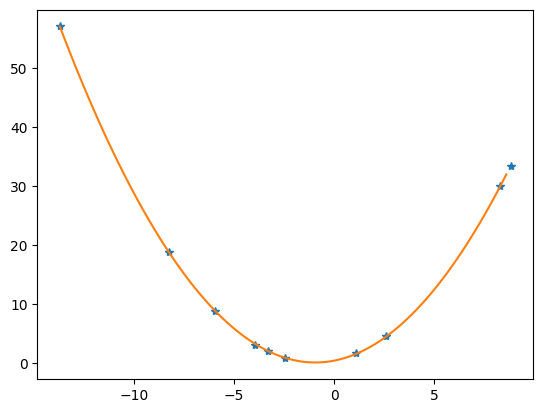

In [1]:
import numpy as np
from matplotlib import pyplot as plt
n = 10
x = np.random.randn(n)*10
X = np.array([np.power(x,0),np.power(x,1),np.power(x,2)]).T
# h = b0*x^0 + b1*x^1 + b2*x^2
beta = np.random.rand(3,1)
y = np.add(np.dot(X,beta),np.random.randn(n,1)*0.1)
print(X)
print(y)
print(beta)
beta_estimado = np.dot(np.dot(np.linalg.inv(np.dot(X.T,X)),X.T),y)
print(beta_estimado)
plt.plot(x,y,'*')
mix = np.min(x)
max = np.max(x)
x_prueba = np.arange(100)/100*(max-mix)+mix
X_prueba = np.array([np.power(x_prueba,0),np.power(x_prueba,1),np.power(x_prueba,2)]).T
y_estimado = np.dot(X_prueba,beta_estimado)
plt.plot(x_prueba,y_estimado)

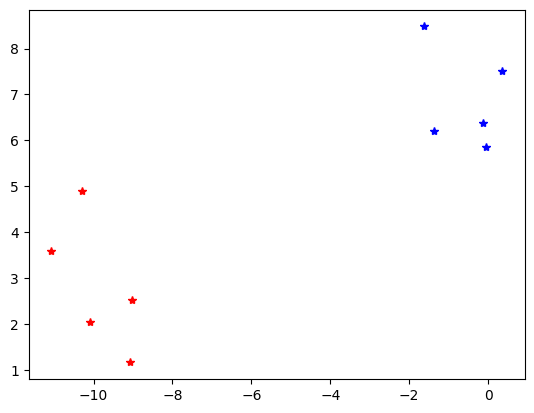

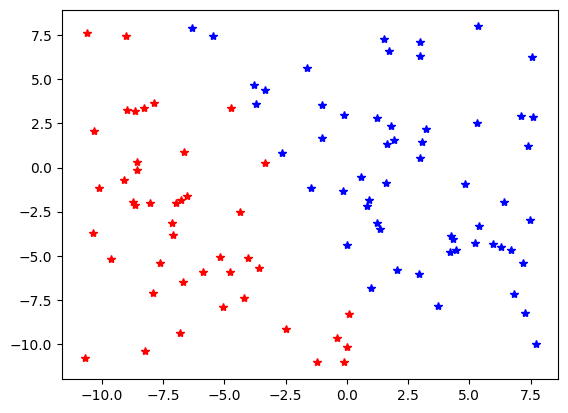

In [21]:
import numpy as np
from matplotlib import pyplot as plt
from sklearn.datasets import make_blobs
X, y = make_blobs(n_samples=10, centers=2, n_features=2)
# h = b0 + b1*x1 + b2*x2
y[y==0] = -1
xr = X[y==-1]
xb = X[y==1]
plt.figure()
plt.plot(xr[:,0],xr[:,1],'*r')
plt.plot(xb[:,0],xb[:,1],'*b')
X1 = np.array([np.ones(len(X[:,0])),X[:,0],X[:,1]]).T
beta_estimado = np.dot(np.dot(np.linalg.inv(np.dot(X1.T,X1)),X1.T),y)
mix = np.min(X1)
max = np.max(X1)
x_prueba1 = np.random.uniform(0,1,100)*(max-mix)+mix
x_prueba2 = np.random.uniform(0,1,100)*(max-mix)+mix
X_prueba = np.array([np.ones(len(x_prueba1)),x_prueba1,x_prueba2]).T
y_estimado = np.dot(X_prueba,beta_estimado)
y_estimado[y_estimado<0] = -1
y_estimado[y_estimado>=0] = 1
xr = X_prueba[y_estimado==-1]
xb = X_prueba[y_estimado==1]
plt.figure()
plt.plot(xr[:,1],xr[:,2],'*r')
plt.plot(xb[:,1],xb[:,2],'*b')
#plt.plot(x_prueba,y_estimado)

In [19]:
x_prueba1

np.float64(303.43930771145034)